# 03 — Exploratory pitch types, validation audit, and final figures

**Research question.** Does the home/road movement difference extend beyond changeups, and does its magnitude vary by pitch type?

Recreates the seven-pitch-type 2024 comparison, runs supporting integrity and Statcast verification checks, and renders the three final publication figures.

**Requires:** outputs from Notebooks 01 and 02. **Important:** the analysis defines *home* by Rockies designated-home status. Two 2024 home games were played in Mexico City, not at Coors Field. Conventional curveballs are `CU`; Freeland and Gomber's `KC` knuckle curves are excluded from that category. The 2D movement metric is the **norm of the mean** horizontal/vertical Statcast movement vector, not an active-spin measurement.

Original charts and outputs are preserved for visual review; fresh-session execution has not been tested in this package.


In [ ]:
%pip -q install pybaseball==2.2.7


In [ ]:
# Shared project configuration — change this path if you use a different Drive folder.
from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np

drive.mount('/content/drive')
PROJECT_DIR = '/content/drive/MyDrive/Coors Project'
DATA_PATH = Path(PROJECT_DIR)
if not DATA_PATH.is_dir():
    raise FileNotFoundError(f'Create or locate your project folder: {DATA_PATH}')
print('Project data:', DATA_PATH)


### Step 21 — Test your gyro-spin hypothesis


In [21]:
# ============================================================
# STEP 21: 2024 ROCKIES — MOVEMENT BY PITCH TYPE
# Test overall horizontal + induced-vertical movement
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path
from pybaseball import statcast_pitcher

DATA_PATH = Path(PROJECT_DIR)
CACHE = DATA_PATH / "Statcast_2024_AllPitches"
CACHE.mkdir(parents=True, exist_ok=True)

master = pd.read_csv(
    DATA_PATH / "coors_master_pitch_types_long.csv"
)

pitch_codes = {
    "four_seam": "FF",
    "sinker": "SI",
    "changeup": "CH",
    "slider": "SL",
    "cutter": "FC",
    "curveball": "CU",
    "sweeper": "ST"
}

for col in ["year", "pa", "usage_percent"]:
    master[col] = pd.to_numeric(master[col], errors="coerce")

# Select pitchers and pitch types by usage,
# without inspecting home-road movement first
eligible = master[
    (master["year"] == 2024)
    & (master["rockies"].astype(str).str.upper() == "Y")
    & (master["pitch_type"].isin(pitch_codes))
    & (master["pa"] >= 100)
    & (master["usage_percent"] >= 5)
][["player_id", "player_name", "pitch_type"]].drop_duplicates()

eligible["statcast_code"] = (
    eligible["pitch_type"].map(pitch_codes)
)

results = []
failures = []

print("Eligible pitchers:", eligible["player_id"].nunique())
print("Eligible pitcher-pitch combinations:", len(eligible))

for pid, targets in eligible.groupby("player_id"):

    pid = int(pid)
    name = targets["player_name"].iloc[0]

    print(f"Checking {name}")

    cache_file = CACHE / f"{pid}_2024_COL_all.csv"

    try:
        if cache_file.exists():
            pitches = pd.read_csv(cache_file)
        else:
            raw = statcast_pitcher(
                start_dt="2024-03-01",
                end_dt="2024-10-05",
                player_id=pid
            )

            if raw is None or raw.empty:
                raise ValueError("No pitch records")

            half = (
                raw["inning_topbot"]
                .astype(str)
                .str.lower()
            )

            # Home team pitches in top half;
            # away team pitches in bottom half
            pitching_for_col = (
                ((raw["home_team"] == "COL")
                 & half.str.startswith("top"))
                |
                ((raw["away_team"] == "COL")
                 & half.str.startswith("bot"))
            )

            pitches = raw.loc[
                pitching_for_col
                & (raw["game_type"] == "R"),
                [
                    "game_pk",
                    "pitch_type",
                    "home_team",
                    "pfx_x",
                    "pfx_z"
                ]
            ].copy()

            pitches["environment"] = np.where(
                pitches["home_team"] == "COL",
                "Home",
                "Road"
            )

            pitches.to_csv(cache_file, index=False)

        for col in ["pfx_x", "pfx_z"]:
            pitches[col] = pd.to_numeric(
                pitches[col], errors="coerce"
            )

        for target in targets.itertuples(index=False):

            subset = pitches[
                pitches["pitch_type"] == target.statcast_code
            ].dropna(subset=["pfx_x", "pfx_z"]).copy()

            if subset.empty:
                continue

            summary = (
                subset.groupby("environment")
                .agg(
                    pitches=("game_pk", "size"),
                    games=("game_pk", "nunique"),
                    horizontal=("pfx_x", "mean"),
                    vertical=("pfx_z", "mean")
                )
            )

            if not {"Home", "Road"}.issubset(summary.index):
                continue

            home = summary.loc["Home"]
            road = summary.loc["Road"]

            # Statcast pfx measurements are in feet
            home_h = home["horizontal"] * 12
            road_h = road["horizontal"] * 12
            home_v = home["vertical"] * 12
            road_v = road["vertical"] * 12

            home_total = np.hypot(home_h, home_v)
            road_total = np.hypot(road_h, road_v)

            sufficient = (
                home["pitches"] >= 20
                and road["pitches"] >= 20
                and home["games"] >= 3
                and road["games"] >= 3
            )

            results.append({
                "player_id": pid,
                "player_name": name,
                "pitch_type": target.pitch_type,
                "home_pitches": int(home["pitches"]),
                "road_pitches": int(road["pitches"]),
                "home_games": int(home["games"]),
                "road_games": int(road["games"]),
                "home_total_movement": home_total,
                "road_total_movement": road_total,
                "movement_difference": (
                    home_total - road_total
                ),
                "pct_difference": (
                    100 * (home_total - road_total) / road_total
                    if road_total > 0 else np.nan
                ),
                "horizontal_difference": (
                    abs(home_h) - abs(road_h)
                ),
                "vertical_difference": home_v - road_v,
                "sufficient_sample": sufficient
            })

    except Exception as exc:
        failures.append({
            "player_name": name,
            "error": str(exc)
        })

# ------------------------------------------------------------
# Summarize qualifying pitcher-pitch comparisons
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\n" + "=" * 65)
print("2024 ROCKIES — HOME VS ROAD BY PITCH TYPE")
print("=" * 65)

print("Successful pitcher-pitch comparisons:", len(results_df))
print("Retrieval failures:", len(failures))

if not results_df.empty:

    valid = results_df[
        results_df["sufficient_sample"]
    ].copy()

    summary = (
        valid.groupby("pitch_type")
        .agg(
            pitchers=("player_id", "nunique"),
            avg_road_movement=(
                "road_total_movement", "mean"
            ),
            avg_home_movement=(
                "home_total_movement", "mean"
            ),
            mean_difference=(
                "movement_difference", "mean"
            ),
            median_difference=(
                "movement_difference", "median"
            ),
            mean_pct_difference=(
                "pct_difference", "mean"
            ),
            pct_less_movement=(
                "movement_difference",
                lambda x: 100 * (x < 0).mean()
            )
        )
        .reset_index()
        .sort_values("mean_difference")
    )

    print("\nOVERALL MOVEMENT MAGNITUDE")
    display(summary.round(2))

    print("\nINDIVIDUAL PITCHER-PITCH RESULTS")
    display(
        valid.sort_values(
            ["pitch_type", "movement_difference"]
        ).round(2)
    )

    # Check against our previous changeup analysis
    ch = valid[valid["pitch_type"] == "changeup"]

    if not ch.empty:
        print(
            "\nChangeup horizontal difference (validation):",
            round(ch["horizontal_difference"].mean(), 2),
            "inches"
        )

    summary.to_csv(
        DATA_PATH / "coors_2024_pitch_type_movement_summary.csv",
        index=False
    )

    results_df.to_csv(
        DATA_PATH / "coors_2024_pitch_type_movement_detail.csv",
        index=False
    )

if failures:
    print("\nFAILED RETRIEVALS")
    display(pd.DataFrame(failures))

Eligible pitchers: 17
Eligible pitcher-pitch combinations: 61
Checking Gomber, Austin
Checking Freeland, Kyle
Checking Quantrill, Cal
Checking Blach, Ty
Checking Hudson, Dakota
Checking Kinley, Tyler
Checking Beeks, Jalen
Checking Bird, Jake
Checking Feltner, Ryan
Checking Lambert, Peter
Checking Lawrence, Justin
Checking Vodnik, Victor
Checking Mears, Nick
Checking Chivilli, Angel
Checking Molina, Anthony
Checking Gordon, Tanner
Checking Blalock, Bradley

2024 ROCKIES — HOME VS ROAD BY PITCH TYPE
Successful pitcher-pitch comparisons: 59
Retrieval failures: 0

OVERALL MOVEMENT MAGNITUDE


,pitch_type,pitchers,avg_road_movement,avg_home_movement,mean_difference,median_difference,mean_pct_difference,pct_less_movement
4,sinker,7,17.08,13.14,-3.93,-3.94,-23.17,100.0
0,changeup,10,15.28,11.59,-3.69,-3.83,-23.49,100.0
3,four_seam,12,17.91,14.37,-3.55,-3.55,-20.05,100.0
1,curveball,7,11.44,9.07,-2.37,-2.11,-21.64,100.0
6,sweeper,2,14.20,12.47,-1.74,-1.74,-12.38,100.0
5,slider,10,6.02,4.70,-1.32,-1.12,-20.01,100.0
2,cutter,5,6.22,5.08,-1.14,-1.29,-11.14,80.0



INDIVIDUAL PITCHER-PITCH RESULTS


,player_id,player_name,pitch_type,home_pitches,road_pitches,home_games,road_games,home_total_movement,road_total_movement,movement_difference,pct_difference,horizontal_difference,vertical_difference,sufficient_sample
14,621389,"Blach, Ty",changeup,206,72,13,7,12.79,17.61,-4.83,-27.40,-4.92,-1.13,True
48,683409,"Chivilli, Angel",changeup,133,73,17,12,10.81,15.27,-4.47,-29.24,-3.03,-3.65,True
19,641712,"Hudson, Dakota",changeup,94,58,10,8,11.21,15.51,-4.30,-27.73,-4.45,0.25,True
37,663567,"Lambert, Peter",changeup,104,156,11,16,10.90,15.00,-4.09,-27.29,-3.87,-1.44,True
2,596295,"Gomber, Austin",changeup,240,298,14,16,12.36,16.24,-3.88,-23.90,-3.04,-2.46,True
52,683627,"Molina, Anthony",changeup,115,120,16,16,13.54,17.32,-3.78,-21.82,-2.96,-2.42,True
24,656222,"Beeks, Jalen",changeup,75,138,22,21,14.68,18.37,-3.69,-20.07,-3.83,-0.77,True
6,607536,"Freeland, Kyle",changeup,83,123,10,11,11.23,14.84,-3.61,-24.30,-3.08,-1.92,True
42,680767,"Vodnik, Victor",changeup,111,111,30,29,11.37,14.84,-3.47,-23.40,-3.48,0.49,True
34,663372,"Feltner, Ryan",changeup,190,189,15,15,7.05,7.81,-0.76,-9.79,-0.91,-0.13,True



Changeup horizontal difference (validation): -3.36 inches


## Publication figures

These figures are generated from previously saved results; they do not refit a model.

### Visualization 1


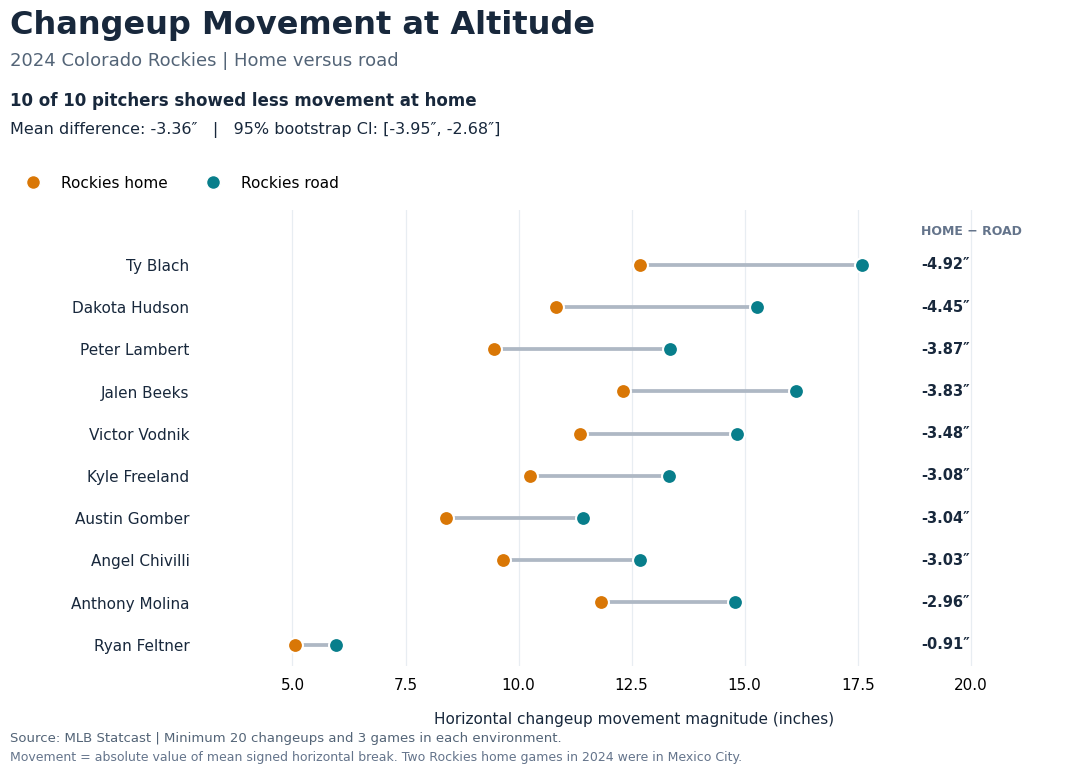

Figure 1 saved:
/content/drive/MyDrive/Coors Project/figures/figure_1_changeup_home_road.png
/content/drive/MyDrive/Coors Project/figures/figure_1_changeup_home_road.pdf


In [26]:
# ============================================================
# FIGURE 1 — 2024 ROCKIES CHANGEUP MOVEMENT
# Publication-ready connected-dot chart
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

DATA_PATH = Path(PROJECT_DIR)
FIGURE_PATH = DATA_PATH / "figures"
FIGURE_PATH.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load audited research results
# ------------------------------------------------------------

df = pd.read_csv(
    DATA_PATH / "coors_2024_changeup_validation.csv"
)

stats = pd.read_csv(
    DATA_PATH / "coors_changeup_final_statistics.csv"
)

valid = df[
    df["sufficient_sample"]
    .astype(str).str.lower().eq("true")
].copy()

assert len(valid) == 10
assert valid["player_id"].nunique() == 10

valid = valid.sort_values("difference").reset_index(drop=True)

def format_name(name):
    if ", " in name:
        last, first = name.split(", ", 1)
        return f"{first} {last}"
    return name

valid["display_name"] = valid["player_name"].map(format_name)

mean_diff = float(stats["mean_difference"].iloc[0])
ci_lower = float(stats["ci_lower"].iloc[0])
ci_upper = float(stats["ci_upper"].iloc[0])

# ------------------------------------------------------------
# 2. Professional chart styling
# ------------------------------------------------------------

HOME = "#D97706"
ROAD = "#087E8B"
NAVY = "#18283C"
GREY = "#AEB8C4"
LIGHT = "#E8EDF2"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "savefig.facecolor": "white"
})

fig, ax = plt.subplots(figsize=(12, 8))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

y = np.arange(len(valid))

# ------------------------------------------------------------
# 3. Plot individual pitcher comparisons
# ------------------------------------------------------------

for i, row in valid.iterrows():

    home = row["home_movement"]
    road = row["road_movement"]

    # Connect the two environments
    ax.plot(
        [home, road],
        [i, i],
        color=GREY,
        linewidth=2.7,
        solid_capstyle="round",
        zorder=2
    )

    # Coors-designated home
    ax.scatter(
        home, i,
        s=115,
        color=HOME,
        edgecolor="white",
        linewidth=1.5,
        zorder=4
    )

    # Rockies road
    ax.scatter(
        road, i,
        s=115,
        color=ROAD,
        edgecolor="white",
        linewidth=1.5,
        zorder=4
    )

# ------------------------------------------------------------
# 4. Difference column
# ------------------------------------------------------------

max_movement = valid[
    ["home_movement", "road_movement"]
].max().max()

difference_x = max_movement + 1.3

for i, row in valid.iterrows():

    ax.text(
        difference_x,
        i,
        f'{row["difference"]:+.2f}″',
        ha="left",
        va="center",
        fontsize=10.5,
        weight="bold",
        color=NAVY
    )

ax.text(
    difference_x,
    -0.8,
    "HOME − ROAD",
    ha="left",
    va="center",
    fontsize=9,
    weight="bold",
    color="#64748B"
)

# ------------------------------------------------------------
# 5. Axes and labels
# ------------------------------------------------------------

ax.set_yticks(y)
ax.set_yticklabels(
    valid["display_name"],
    fontsize=11,
    color=NAVY
)

ax.set_ylim(len(valid) - 0.5, -1.3)

ax.set_xlim(3, max_movement + 4.5)

ax.set_xlabel(
    "Horizontal changeup movement magnitude (inches)",
    fontsize=11,
    color=NAVY,
    labelpad=13
)

ax.grid(
    axis="x",
    color=LIGHT,
    linewidth=0.9
)

ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, pad=9)

for spine in ax.spines.values():
    spine.set_visible(False)

# ------------------------------------------------------------
# 6. Titles and findings
# ------------------------------------------------------------

fig.text(
    0.07, 0.95,
    "Changeup Movement at Altitude",
    fontsize=23,
    fontweight="bold",
    color=NAVY
)

fig.text(
    0.07, 0.91,
    "2024 Colorado Rockies | Home versus road",
    fontsize=13,
    color="#536477"
)

fig.text(
    0.07, 0.86,
    f"10 of 10 pitchers showed less movement at home",
    fontsize=12,
    fontweight="bold",
    color=NAVY
)

fig.text(
    0.07, 0.825,
    f"Mean difference: {mean_diff:.2f}″   "
    f"|   95% bootstrap CI: "
    f"[{ci_lower:.2f}″, {ci_upper:.2f}″]",
    fontsize=11.5,
    color=NAVY
)

# ------------------------------------------------------------
# 7. Legend
# ------------------------------------------------------------

legend_items = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=HOME,
        markeredgecolor="white",
        markersize=10,
        label="Rockies home"
    ),
    Line2D(
        [0], [0],
        marker="o",
        linestyle="None",
        markerfacecolor=ROAD,
        markeredgecolor="white",
        markersize=10,
        label="Rockies road"
    )
]

fig.legend(
    handles=legend_items,
    loc="upper left",
    bbox_to_anchor=(0.065, 0.79),
    frameon=False,
    ncol=2,
    fontsize=11
)

# ------------------------------------------------------------
# 8. Research footnotes
# ------------------------------------------------------------

fig.text(
    0.07, 0.065,
    "Source: MLB Statcast | Minimum 20 changeups and "
    "3 games in each environment.",
    fontsize=9.5,
    color="#536477"
)

fig.text(
    0.07, 0.041,
    "Movement = absolute value of mean signed horizontal "
    "break. Two Rockies home games in 2024 were in Mexico City.",
    fontsize=9,
    color="#64748B"
)

fig.subplots_adjust(
    left=0.23,
    right=0.95,
    top=0.73,
    bottom=0.16
)

# ------------------------------------------------------------
# 9. Save high-resolution publication files
# ------------------------------------------------------------

png_path = FIGURE_PATH / "figure_1_changeup_home_road.png"
pdf_path = FIGURE_PATH / "figure_1_changeup_home_road.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure 1 saved:")
print(png_path)
print(pdf_path)

### Figure 2 — Movement differences across seven pitch types


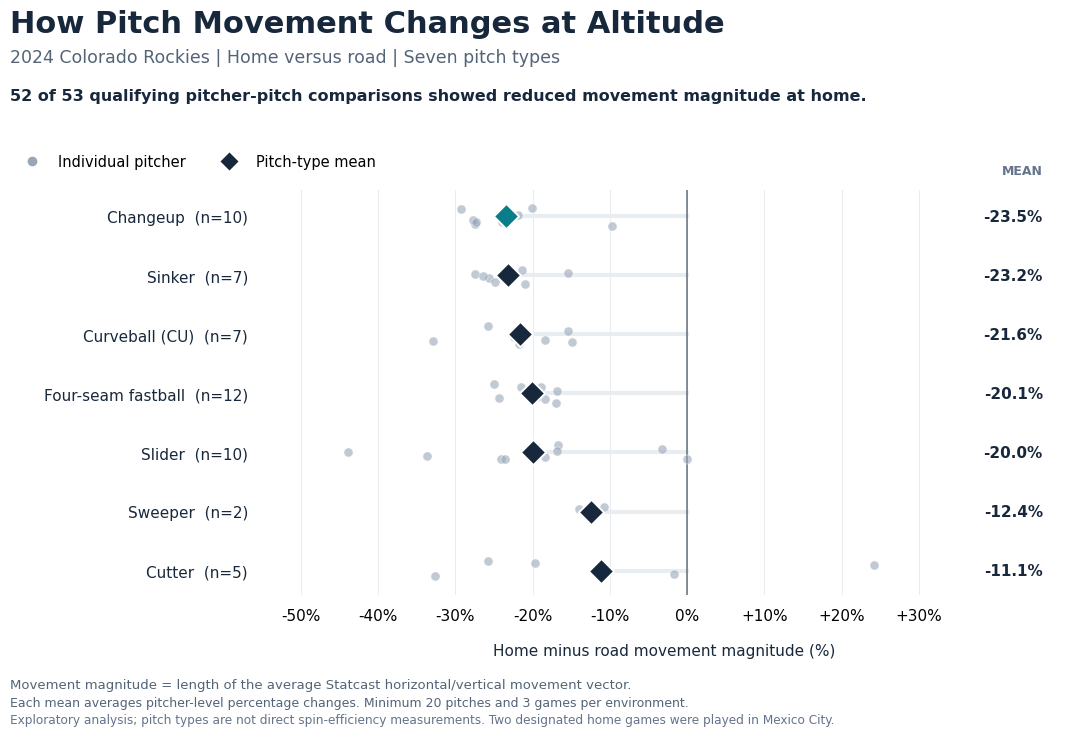

Figure 2 saved:
/content/drive/MyDrive/Coors Project/figures/figure_2_pitch_type_comparison.png
/content/drive/MyDrive/Coors Project/figures/figure_2_pitch_type_comparison.pdf

PITCH-TYPE SUMMARY


,pitch_type,pitchers,mean_pct,lower_at_home
0,changeup,10,-23.49,10
1,sinker,7,-23.17,7
2,curveball,7,-21.64,7
3,four_seam,12,-20.05,12
4,slider,10,-20.01,10
5,sweeper,2,-12.38,2
6,cutter,5,-11.14,4


In [27]:
# ============================================================
# FIGURE 2 — MOVEMENT DIFFERENCES BY PITCH TYPE
# Publication-quality exploratory comparison
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

DATA_PATH = Path(PROJECT_DIR)
FIGURE_PATH = DATA_PATH / "figures"
FIGURE_PATH.mkdir(parents=True, exist_ok=True)

# 1. Load audited results
df = pd.read_csv(
    DATA_PATH / "coors_2024_pitch_type_movement_detail.csv"
)

valid = df[
    df["sufficient_sample"]
    .astype(str).str.lower().eq("true")
].copy()

assert len(valid) == 53

summary = (
    valid.groupby("pitch_type")
    .agg(
        pitchers=("player_id", "nunique"),
        mean_pct=("pct_difference", "mean"),
        lower_at_home=(
            "pct_difference",
            lambda x: int((x < 0).sum())
        )
    )
    .reset_index()
    .sort_values("mean_pct")
    .reset_index(drop=True)
)

labels = {
    "four_seam": "Four-seam fastball",
    "sinker": "Sinker",
    "changeup": "Changeup",
    "curveball": "Curveball (CU)",
    "slider": "Slider",
    "cutter": "Cutter",
    "sweeper": "Sweeper"
}

# 2. Styling
NAVY = "#18283C"
TEAL = "#087E8B"
GREY = "#98A7B8"
LIGHT = "#E8EDF2"

fig, ax = plt.subplots(figsize=(12, 7.5))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

rng = np.random.default_rng(42)

# 3. Plot each pitch type
for i, row in summary.iterrows():

    pitch = row["pitch_type"]
    values = valid.loc[
        valid["pitch_type"] == pitch,
        "pct_difference"
    ].to_numpy()

    # Individual observations, slightly offset vertically
    jitter = rng.uniform(-0.17, 0.17, len(values))

    ax.scatter(
        values,
        i + jitter,
        s=43,
        color=GREY,
        alpha=0.60,
        edgecolor="white",
        linewidth=0.5,
        zorder=3
    )

    mean = row["mean_pct"]

    # Connect mean to zero
    ax.plot(
        [mean, 0],
        [i, i],
        color=LIGHT,
        linewidth=3,
        zorder=1
    )

    # Mean marker
    ax.scatter(
        mean, i,
        s=165,
        marker="D",
        color=TEAL if pitch == "changeup" else NAVY,
        edgecolor="white",
        linewidth=1.4,
        zorder=5
    )

    # Dedicated mean-value column
    ax.text(
        46, i,
        f"{mean:+.1f}%",
        ha="right",
        va="center",
        fontsize=11,
        fontweight="bold",
        color=NAVY
    )

# 4. Axes
y = np.arange(len(summary))

ax.set_yticks(y)
ax.set_yticklabels(
    [
        f"{labels[row.pitch_type]}  (n={row.pitchers})"
        for row in summary.itertuples()
    ],
    fontsize=11,
    color=NAVY
)

ax.invert_yaxis()

ax.set_xlim(-55, 49)

ax.axvline(
    0,
    color=NAVY,
    linewidth=1.2,
    alpha=0.6
)

ax.set_xticks([-50, -40, -30, -20, -10, 0, 10, 20, 30])
ax.set_xticklabels(
    ["-50%", "-40%", "-30%", "-20%", "-10%",
     "0%", "+10%", "+20%", "+30%"]
)

ax.grid(axis="x", color=LIGHT, linewidth=0.8)
ax.set_axisbelow(True)

ax.tick_params(axis="both", length=0, pad=10)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xlabel(
    "Home minus road movement magnitude (%)",
    fontsize=11,
    color=NAVY,
    labelpad=14
)

ax.text(
    46, -0.72,
    "MEAN",
    ha="right",
    fontsize=9,
    fontweight="bold",
    color="#64748B"
)

# 5. Title and subtitle
fig.text(
    0.07, 0.95,
    "How Pitch Movement Changes at Altitude",
    fontsize=22,
    fontweight="bold",
    color=NAVY
)

fig.text(
    0.07, 0.91,
    "2024 Colorado Rockies | Home versus road | Seven pitch types",
    fontsize=12.5,
    color="#536477"
)

fig.text(
    0.07, 0.86,
    "52 of 53 qualifying pitcher-pitch comparisons "
    "showed reduced movement magnitude at home.",
    fontsize=11.5,
    fontweight="bold",
    color=NAVY
)

# 6. Legend
legend_items = [
    Line2D(
        [0], [0], marker="o", linestyle="None",
        markerfacecolor=GREY, markeredgecolor="white",
        markersize=8, label="Individual pitcher"
    ),
    Line2D(
        [0], [0], marker="D", linestyle="None",
        markerfacecolor=NAVY, markeredgecolor="white",
        markersize=10, label="Pitch-type mean"
    )
]

fig.legend(
    handles=legend_items,
    loc="upper left",
    bbox_to_anchor=(0.065, 0.805),
    frameon=False,
    ncol=2,
    fontsize=10.5
)

# 7. Notes
fig.text(
    0.07, 0.075,
    "Movement magnitude = length of the average Statcast "
    "horizontal/vertical movement vector.",
    fontsize=9.5,
    color="#536477"
)

fig.text(
    0.07, 0.052,
    "Each mean averages pitcher-level percentage changes. "
    "Minimum 20 pitches and 3 games per environment.",
    fontsize=9,
    color="#536477"
)

fig.text(
    0.07, 0.029,
    "Exploratory analysis; pitch types are not direct spin-efficiency "
    "measurements. Two designated home games were played in Mexico City.",
    fontsize=8.7,
    color="#64748B"
)

fig.subplots_adjust(
    left=0.28,
    right=0.95,
    top=0.74,
    bottom=0.20
)

# 8. Save
png_path = FIGURE_PATH / "figure_2_pitch_type_comparison.png"
pdf_path = FIGURE_PATH / "figure_2_pitch_type_comparison.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure 2 saved:")
print(png_path)
print(pdf_path)

print("\nPITCH-TYPE SUMMARY")
display(summary.round(2))

### Figure 3 — Is the Rockies changeup difference ordinary MLB variation?


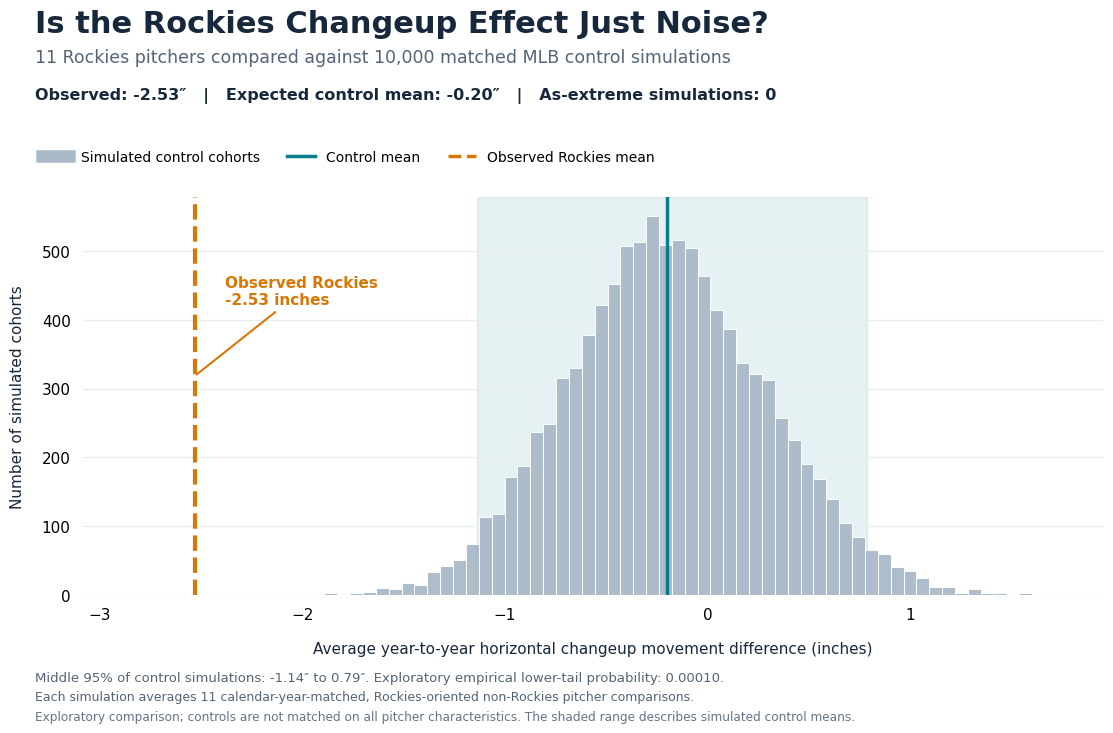


FIGURE 3 SUMMARY
Rockies pitchers: 11
Simulated cohorts: 10000
Observed Rockies mean: -2.532
Control mean: -0.201
Control central 95%: [-1.136  0.791]
Simulations as extreme as observed: 0
Exploratory empirical probability: 0.0001

Figure 3 saved:
/content/drive/MyDrive/Coors Project/figures/figure_3_changeup_control_simulation.png
/content/drive/MyDrive/Coors Project/figures/figure_3_changeup_control_simulation.pdf


In [28]:
# ============================================================
# FIGURE 3 — ROCKIES VS MLB YEAR-TO-YEAR VARIATION
# Publication-ready simulation histogram
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

DATA_PATH = Path(PROJECT_DIR)
FIGURE_PATH = DATA_PATH / "figures"
FIGURE_PATH.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Load audited research results
# ------------------------------------------------------------

simulations = pd.read_csv(
    DATA_PATH / "coors_changeup_control_simulations.csv"
)

rockies = pd.read_csv(
    DATA_PATH / "coors_changeup_robustness.csv"
)

control_values = simulations["simulated_mean"].dropna().to_numpy()
rockies_values = rockies["movement_change"].dropna().to_numpy()

assert len(control_values) == 10000
assert len(rockies_values) == 11

observed_mean = rockies_values.mean()
control_mean = control_values.mean()

ci_lower, ci_upper = np.percentile(
    control_values, [2.5, 97.5]
)

more_extreme = int(
    (control_values <= observed_mean).sum()
)

empirical_p = (
    more_extreme + 1
) / (
    len(control_values) + 1
)

# ------------------------------------------------------------
# 2. Professional styling
# ------------------------------------------------------------

NAVY = "#18283C"
TEAL = "#087E8B"
ORANGE = "#D97706"
LIGHT = "#E8EDF2"
HIST = "#AABAC9"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "savefig.facecolor": "white"
})

fig, ax = plt.subplots(figsize=(12, 7.5))

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# ------------------------------------------------------------
# 3. Plot simulated control distribution
# ------------------------------------------------------------

ax.hist(
    control_values,
    bins=55,
    color=HIST,
    edgecolor="white",
    linewidth=0.7,
    alpha=0.95,
    zorder=2
)

# Central 95% of control simulations
ax.axvspan(
    ci_lower,
    ci_upper,
    color=TEAL,
    alpha=0.10,
    zorder=0
)

# Control mean
ax.axvline(
    control_mean,
    color=TEAL,
    linewidth=2.5,
    zorder=4
)

# Actual Rockies result
ax.axvline(
    observed_mean,
    color=ORANGE,
    linewidth=3,
    linestyle="--",
    zorder=5
)

# ------------------------------------------------------------
# 4. Axes
# ------------------------------------------------------------

x_min = min(
    observed_mean - 0.55,
    control_values.min() - 0.3
)

x_max = control_values.max() + 0.35

ax.set_xlim(x_min, x_max)

ax.set_xlabel(
    "Average year-to-year horizontal changeup "
    "movement difference (inches)",
    fontsize=11,
    color=NAVY,
    labelpad=14
)

ax.set_ylabel(
    "Number of simulated cohorts",
    fontsize=11,
    color=NAVY,
    labelpad=12
)

ax.grid(
    axis="y",
    color=LIGHT,
    linewidth=0.9
)

ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, pad=9)

for spine in ax.spines.values():
    spine.set_visible(False)

# Label the observed result near its vertical line
y_max = ax.get_ylim()[1]

ax.annotate(
    f"Observed Rockies\n{observed_mean:.2f} inches",
    xy=(observed_mean, y_max * 0.55),
    xytext=(observed_mean + 0.15, y_max * 0.73),
    fontsize=11,
    fontweight="bold",
    color=ORANGE,
    ha="left",
    arrowprops={
        "arrowstyle": "-",
        "color": ORANGE,
        "linewidth": 1.5
    }
)

# ------------------------------------------------------------
# 5. Titles and summary
# ------------------------------------------------------------

fig.text(
    0.07, 0.95,
    "Is the Rockies Changeup Effect Just Noise?",
    fontsize=22,
    fontweight="bold",
    color=NAVY
)

fig.text(
    0.07, 0.91,
    "11 Rockies pitchers compared against "
    "10,000 matched MLB control simulations",
    fontsize=12.5,
    color="#536477"
)

fig.text(
    0.07, 0.86,
    f"Observed: {observed_mean:.2f}″   "
    f"|   Expected control mean: {control_mean:.2f}″   "
    f"|   As-extreme simulations: {more_extreme:,}",
    fontsize=11.5,
    fontweight="bold",
    color=NAVY
)

# ------------------------------------------------------------
# 6. Legend
# ------------------------------------------------------------

legend_items = [
    Line2D(
        [0], [0],
        color=HIST,
        linewidth=9,
        label="Simulated control cohorts"
    ),
    Line2D(
        [0], [0],
        color=TEAL,
        linewidth=2.5,
        label="Control mean"
    ),
    Line2D(
        [0], [0],
        color=ORANGE,
        linewidth=2.5,
        linestyle="--",
        label="Observed Rockies mean"
    )
]

fig.legend(
    handles=legend_items,
    loc="upper left",
    bbox_to_anchor=(0.065, 0.81),
    frameon=False,
    ncol=3,
    fontsize=10
)

# ------------------------------------------------------------
# 7. Research footnotes
# ------------------------------------------------------------

fig.text(
    0.07, 0.085,
    f"Middle 95% of control simulations: "
    f"{ci_lower:.2f}″ to {ci_upper:.2f}″. "
    f"Exploratory empirical lower-tail probability: "
    f"{empirical_p:.5f}.",
    fontsize=9.5,
    color="#536477"
)

fig.text(
    0.07, 0.059,
    "Each simulation averages 11 calendar-year-matched, "
    "Rockies-oriented non-Rockies pitcher comparisons.",
    fontsize=9,
    color="#536477"
)

fig.text(
    0.07, 0.033,
    "Exploratory comparison; controls are not matched "
    "on all pitcher characteristics. "
    "The shaded range describes simulated control means.",
    fontsize=8.7,
    color="#64748B"
)

fig.subplots_adjust(
    left=0.11,
    right=0.96,
    top=0.73,
    bottom=0.20
)

# ------------------------------------------------------------
# 8. Save publication files
# ------------------------------------------------------------

png_path = FIGURE_PATH / "figure_3_changeup_control_simulation.png"
pdf_path = FIGURE_PATH / "figure_3_changeup_control_simulation.pdf"

fig.savefig(
    png_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    pdf_path,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nFIGURE 3 SUMMARY")
print("Rockies pitchers:", len(rockies_values))
print("Simulated cohorts:", len(control_values))
print("Observed Rockies mean:", round(observed_mean, 3))
print("Control mean:", round(control_mean, 3))
print(
    "Control central 95%:",
    np.round([ci_lower, ci_upper], 3)
)
print("Simulations as extreme as observed:", more_extreme)
print("Exploratory empirical probability:", round(empirical_p, 6))

print("\nFigure 3 saved:")
print(png_path)
print(pdf_path)

## Technical appendix — integrity and measurement audits

These checks document sample accounting, team assignments, game venue caveats, and cross-output consistency.

## Methodological audit


In [22]:
# ============================================================
# METHODOLOGICAL AUDIT 1
# DATASET INTEGRITY AND SAMPLE ACCOUNTING
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path(PROJECT_DIR)

master = pd.read_csv(
    DATA_PATH / "coors_master_pitch_types_long.csv"
)

results = pd.read_csv(
    DATA_PATH / "coors_2024_pitch_type_movement_detail.csv"
)

# ------------------------------------------------------------
# 1. Reconstruct eligibility
# ------------------------------------------------------------

for col in ["year", "pa", "usage_percent"]:
    master[col] = pd.to_numeric(master[col], errors="coerce")

pitch_types = [
    "four_seam", "sinker", "changeup",
    "slider", "cutter", "curveball", "sweeper"
]

eligible = master[
    (master["year"] == 2024)
    & (master["rockies"].astype(str).str.upper() == "Y")
    & (master["pitch_type"].isin(pitch_types))
    & (master["pa"] >= 100)
    & (master["usage_percent"] >= 5)
][
    ["player_id", "player_name", "pitch_type"]
].drop_duplicates()

print("=" * 60)
print("AUDIT 1 — DATASET INTEGRITY")
print("=" * 60)

print("Eligible pitchers:", eligible["player_id"].nunique())
print("Eligible pitcher-pitch combinations:", len(eligible))
print("Calculated comparisons:", len(results))

# ------------------------------------------------------------
# 2. Check duplicate comparisons
# ------------------------------------------------------------

duplicates = results[
    results.duplicated(
        ["player_id", "pitch_type"],
        keep=False
    )
]

print("\nDUPLICATE COMPARISONS:", len(duplicates))

if not duplicates.empty:
    display(duplicates)

# ------------------------------------------------------------
# 3. Identify eligible comparisons missing from results
# ------------------------------------------------------------

missing = eligible.merge(
    results[["player_id", "pitch_type"]],
    on=["player_id", "pitch_type"],
    how="left",
    indicator=True
)

missing = missing[
    missing["_merge"] == "left_only"
].drop(columns="_merge")

print("\nELIGIBLE COMBINATIONS WITHOUT COMPARISONS:")
display(missing)

# ------------------------------------------------------------
# 4. Recalculate qualification flags
# ------------------------------------------------------------

results["audit_qualifies"] = (
    (results["home_pitches"] >= 20)
    & (results["road_pitches"] >= 20)
    & (results["home_games"] >= 3)
    & (results["road_games"] >= 3)
)

original_flags = (
    results["sufficient_sample"]
    .astype(str)
    .str.lower()
    .eq("true")
)

print(
    "\nQualification flag mismatches:",
    int((original_flags != results["audit_qualifies"]).sum())
)

print("\nCOMPARISONS NOT MEETING SAMPLE REQUIREMENTS")

display(
    results.loc[
        ~results["audit_qualifies"],
        [
            "player_name",
            "pitch_type",
            "home_pitches",
            "road_pitches",
            "home_games",
            "road_games"
        ]
    ]
)

# ------------------------------------------------------------
# 5. Verify movement calculations
# ------------------------------------------------------------

expected_difference = (
    results["home_total_movement"]
    - results["road_total_movement"]
)

expected_pct = (
    100 * expected_difference
    / results["road_total_movement"]
)

difference_error = (
    results["movement_difference"]
    - expected_difference
).abs()

percentage_error = (
    results["pct_difference"]
    - expected_pct
).abs()

print("\nCALCULATION ACCURACY")

print(
    "Largest movement difference discrepancy:",
    round(difference_error.max(), 8)
)

print(
    "Largest percentage discrepancy:",
    round(percentage_error.max(), 8)
)

# ------------------------------------------------------------
# 6. Final sample accounting
# ------------------------------------------------------------

valid = results[results["audit_qualifies"]].copy()

print("\nFINAL SAMPLE ACCOUNTING")
print("-" * 60)

print("Eligible combinations:", len(eligible))
print("Calculated comparisons:", len(results))
print("Qualified comparisons:", len(valid))

print(
    "Qualified comparisons showing lower home movement:",
    int((valid["movement_difference"] < 0).sum())
)

print("\nQUALIFYING OBSERVATIONS BY PITCH TYPE")

summary = (
    valid.groupby("pitch_type")
    .agg(
        pitchers=("player_id", "nunique"),
        observations=("player_id", "size"),
        lower_home_movement=(
            "movement_difference",
            lambda x: int((x < 0).sum())
        ),
        mean_difference=("movement_difference", "mean"),
        mean_pct_difference=("pct_difference", "mean")
    )
    .reset_index()
)

display(summary.round(2))

# ------------------------------------------------------------
# 7. Automated integrity checks
# ------------------------------------------------------------

assert duplicates.empty, "Duplicate comparisons detected."

assert (
    original_flags == results["audit_qualifies"]
).all(), "Qualification flag mismatch."

assert difference_error.max() < 0.01, (
    "Movement difference calculation discrepancy."
)

assert percentage_error.max() < 0.05, (
    "Percentage calculation discrepancy."
)

print("\nBASIC INTEGRITY CHECKS PASSED")

AUDIT 1 — DATASET INTEGRITY
Eligible pitchers: 17
Eligible pitcher-pitch combinations: 61
Calculated comparisons: 59

DUPLICATE COMPARISONS: 0

ELIGIBLE COMBINATIONS WITHOUT COMPARISONS:


,player_id,player_name,pitch_type
40,607536,"Freeland, Kyle",curveball
44,596295,"Gomber, Austin",curveball



Qualification flag mismatches: 0

COMPARISONS NOT MEETING SAMPLE REQUIREMENTS


,player_name,pitch_type,home_pitches,road_pitches,home_games,road_games
53,"Gordon, Tanner",four_seam,77,225,2,6
54,"Gordon, Tanner",slider,44,118,2,6
55,"Gordon, Tanner",changeup,37,79,2,6
56,"Blalock, Bradley",four_seam,77,174,2,4
57,"Blalock, Bradley",slider,26,91,2,4
58,"Blalock, Bradley",curveball,24,34,2,4



CALCULATION ACCURACY
Largest movement difference discrepancy: 0.0
Largest percentage discrepancy: 0.0

FINAL SAMPLE ACCOUNTING
------------------------------------------------------------
Eligible combinations: 61
Calculated comparisons: 59
Qualified comparisons: 53
Qualified comparisons showing lower home movement: 52

QUALIFYING OBSERVATIONS BY PITCH TYPE


,pitch_type,pitchers,observations,lower_home_movement,mean_difference,mean_pct_difference
0,changeup,10,10,10,-3.69,-23.49
1,curveball,7,7,7,-2.37,-21.64
2,cutter,5,5,4,-1.14,-11.14
3,four_seam,12,12,12,-3.55,-20.05
4,sinker,7,7,7,-3.93,-23.17
5,slider,10,10,10,-1.32,-20.01
6,sweeper,2,2,2,-1.74,-12.38



BASIC INTEGRITY CHECKS PASSED


### Audit 2 Statcast measurement validation


In [23]:
# ============================================================
# METHODOLOGICAL AUDIT 2
# STATCAST MEASUREMENT AND CLASSIFICATION VALIDATION
# ============================================================

import pandas as pd
import numpy as np
import requests
from pathlib import Path
from pybaseball import statcast_pitcher

DATA_PATH = Path(PROJECT_DIR)
CACHE = DATA_PATH / "Statcast_2024_AllPitches"

results = pd.read_csv(
    DATA_PATH / "coors_2024_pitch_type_movement_detail.csv"
)

PITCH_CODES = {
    "four_seam": "FF",
    "sinker": "SI",
    "changeup": "CH",
    "slider": "SL",
    "cutter": "FC",
    "curveball": "CU",
    "sweeper": "ST"
}

print("=" * 65)
print("AUDIT 2 — STATCAST MEASUREMENT VALIDATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. Load the original cached Statcast pitch records
# ------------------------------------------------------------

cache_by_pitcher = {}

for pid in results["player_id"].unique():

    pid = int(pid)
    file = CACHE / f"{pid}_2024_COL_all.csv"

    if not file.exists():
        raise FileNotFoundError(f"Missing cache: {file}")

    data = pd.read_csv(file)

    for col in ["pfx_x", "pfx_z", "game_pk"]:
        data[col] = pd.to_numeric(
            data[col], errors="coerce"
        )

    cache_by_pitcher[pid] = data

print("\nCached pitcher files:", len(cache_by_pitcher))

# Verify stored home/road labels
invalid_labels = 0

for pid, data in cache_by_pitcher.items():

    invalid_labels += int((
        ((data["environment"] == "Home")
         & (data["home_team"] != "COL"))
        |
        ((data["environment"] == "Road")
         & (data["home_team"] == "COL"))
        |
        (~data["environment"].isin(["Home", "Road"]))
    ).sum())

print("Invalid home/road labels:", invalid_labels)

assert invalid_labels == 0, "Home/road label error"

# ------------------------------------------------------------
# 2. Independently recompute movement measurements
# ------------------------------------------------------------

checks = []

for row in results.itertuples(index=False):

    data = cache_by_pitcher[int(row.player_id)]

    code = PITCH_CODES[row.pitch_type]

    subset = data[
        data["pitch_type"] == code
    ].dropna(subset=["pfx_x", "pfx_z"])

    summary = (
        subset.groupby("environment")
        .agg(
            pitch_count=("game_pk", "size"),
            game_count=("game_pk", "nunique"),
            mean_x=("pfx_x", "mean"),
            mean_z=("pfx_z", "mean")
        )
    )

    if not {"Home", "Road"}.issubset(summary.index):
        raise ValueError(
            f"Missing environment: "
            f"{row.player_name} {row.pitch_type}"
        )

    home = summary.loc["Home"]
    road = summary.loc["Road"]

    # Convert feet to inches, then calculate
    # magnitude of the average movement vector
    home_movement = np.hypot(
        home["mean_x"] * 12,
        home["mean_z"] * 12
    )

    road_movement = np.hypot(
        road["mean_x"] * 12,
        road["mean_z"] * 12
    )

    difference = home_movement - road_movement

    pct_difference = (
        100 * difference / road_movement
        if road_movement > 0 else np.nan
    )

    checks.append({
        "player_name": row.player_name,
        "pitch_type": row.pitch_type,

        "count_matches": (
            int(home["pitch_count"]) == row.home_pitches
            and int(road["pitch_count"]) == row.road_pitches
            and int(home["game_count"]) == row.home_games
            and int(road["game_count"]) == row.road_games
        ),

        "movement_error": max(
            abs(home_movement - row.home_total_movement),
            abs(road_movement - row.road_total_movement),
            abs(difference - row.movement_difference)
        ),

        "percentage_error": abs(
            pct_difference - row.pct_difference
        )
    })

checks_df = pd.DataFrame(checks)

print("\n" + "-" * 55)
print("RECALCULATION VALIDATION")
print("-" * 55)

print("Comparisons independently recalculated:", len(checks_df))
print("Pitch/game counts match:", checks_df["count_matches"].sum())
print(
    "Maximum movement discrepancy:",
    round(checks_df["movement_error"].max(), 8)
)
print(
    "Maximum percentage discrepancy:",
    round(checks_df["percentage_error"].max(), 8)
)

assert checks_df["count_matches"].all()
assert checks_df["movement_error"].max() < 0.001
assert checks_df["percentage_error"].max() < 0.001

print("Recalculation checks PASSED")

# ------------------------------------------------------------
# 3. Verify actual game venues with MLB schedule
# ------------------------------------------------------------

url = "https://statsapi.mlb.com/api/v1/schedule"

response = requests.get(
    url,
    params={
        "teamId": 115,
        "sportId": 1,
        "season": 2024,
        "gameType": "R"
    },
    timeout=45
)

response.raise_for_status()

schedule = response.json()

venue_records = []

for day in schedule.get("dates", []):
    for game in day.get("games", []):

        venue_records.append({
            "game_pk": game["gamePk"],
            "venue": game.get("venue", {}).get("name"),
            "home_team_id": (
                game["teams"]["home"]["team"]["id"]
            ),
            "away_team_id": (
                game["teams"]["away"]["team"]["id"]
            )
        })

venues = pd.DataFrame(venue_records)

if venues.empty:
    raise ValueError("MLB schedule returned no games")

venues = venues.drop_duplicates("game_pk")

all_cached = pd.concat(
    [
        data[["game_pk", "environment"]]
        for data in cache_by_pitcher.values()
    ],
    ignore_index=True
).drop_duplicates()

all_cached = all_cached.merge(
    venues,
    on="game_pk",
    how="left",
    validate="many_to_one"
)

missing_games = all_cached["venue"].isna().sum()

invalid_team_assignment = (
    (
        (all_cached["environment"] == "Home")
        & (all_cached["home_team_id"] != 115)
    )
    |
    (
        (all_cached["environment"] == "Road")
        & (all_cached["away_team_id"] != 115)
    )
).sum()

home_venues = all_cached[
    all_cached["environment"] == "Home"
]

non_coors = home_venues[
    home_venues["venue"] != "Coors Field"
]

print("\n" + "-" * 55)
print("VENUE AND GAME VALIDATION")
print("-" * 55)

print("Unmatched schedule games:", missing_games)
print("Invalid game team assignments:", invalid_team_assignment)

print("\nRockies home-game venues:")
display(home_venues["venue"].value_counts())

print("\nHome games outside Coors Field:")
display(non_coors[["game_pk", "venue"]].drop_duplicates())

# These need to be resolved if nonzero
assert missing_games == 0
assert invalid_team_assignment == 0

# ------------------------------------------------------------
# 4. Check missing curveball pitch classifications
# ------------------------------------------------------------

print("\n" + "-" * 55)
print("CURVEBALL CLASSIFICATION AUDIT")
print("-" * 55)

for pid, name in [
    (607536, "Kyle Freeland"),
    (596295, "Austin Gomber")
]:

    data = cache_by_pitcher[pid]

    curve_codes = data[
        data["pitch_type"].isin(
            ["CU", "KC", "CS"]
        )
    ]

    print(f"\n{name}")

    if curve_codes.empty:
        print("No CU/KC/CS records found")
    else:
        display(
            curve_codes.groupby(
                ["pitch_type", "environment"]
            ).size().unstack(fill_value=0)
        )

# ------------------------------------------------------------
# 5. Verify original team filtering against raw Statcast
# ------------------------------------------------------------

# Two missing-curveball pitchers, plus a traded pitcher.
# This is a spot check, not a complete re-download.
print("\n" + "-" * 55)
print("RAW STATCAST TEAM-ASSIGNMENT SPOT CHECK")
print("-" * 55)

spot_check = {
    607536: "Kyle Freeland",
    596295: "Austin Gomber",
    656222: "Jalen Beeks"
}

for pid, name in spot_check.items():

    print(f"\nChecking raw records: {name}")

    raw = statcast_pitcher(
        start_dt="2024-03-01",
        end_dt="2024-10-05",
        player_id=pid
    )

    if raw is None or raw.empty:
        raise ValueError(f"No raw Statcast data: {name}")

    raw = raw[raw["game_type"] == "R"].copy()

    half = raw["inning_topbot"].astype(str).str.lower()

    top = half.str.startswith("top")
    bottom = half.str.startswith("bot")

    # Identify which team was pitching
    raw["pitching_team"] = np.where(
        top,
        raw["home_team"],
        np.where(bottom, raw["away_team"], None)
    )

    raw_col = raw[
        raw["pitching_team"] == "COL"
    ].copy()

    raw_col["environment"] = np.where(
        raw_col["home_team"] == "COL",
        "Home",
        "Road"
    )

    cached = cache_by_pitcher[pid]

    # Match pitch counts by game, environment and pitch type
    keys = ["game_pk", "environment", "pitch_type"]

    raw_counts = (
        raw_col.groupby(keys, dropna=False)
        .size().rename("raw_count")
    )

    cache_counts = (
        cached.groupby(keys, dropna=False)
        .size().rename("cache_count")
    )

    comparison = pd.concat(
        [raw_counts, cache_counts],
        axis=1
    ).fillna(0)

    mismatches = (
        comparison["raw_count"]
        != comparison["cache_count"]
    ).sum()

    print("Raw Colorado pitches:", len(raw_col))
    print("Cached Colorado pitches:", len(cached))
    print("Game/pitch-type count mismatches:", mismatches)

    if mismatches:
        display(
            comparison[
                comparison["raw_count"]
                != comparison["cache_count"]
            ].head(15)
        )

    assert mismatches == 0, (
        f"Raw/cached team-filter mismatch: {name}"
    )

print("\n" + "=" * 65)
print("AUDIT 2 CHECKS COMPLETED")
print("=" * 65)

AUDIT 2 — STATCAST MEASUREMENT VALIDATION

Cached pitcher files: 17
Invalid home/road labels: 0

-------------------------------------------------------
RECALCULATION VALIDATION
-------------------------------------------------------
Comparisons independently recalculated: 59
Pitch/game counts match: 59
Maximum movement discrepancy: 0.0
Maximum percentage discrepancy: 0.0
Recalculation checks PASSED

-------------------------------------------------------
VENUE AND GAME VALIDATION
-------------------------------------------------------
Unmatched schedule games: 0
Invalid game team assignments: 0

Rockies home-game venues:


,count
venue,
Coors Field,79
Estadio Alfredo Harp Helu,2



Home games outside Coors Field:


,game_pk,venue
24,746561,Estadio Alfredo Harp Helu
74,746560,Estadio Alfredo Harp Helu



-------------------------------------------------------
CURVEBALL CLASSIFICATION AUDIT
-------------------------------------------------------

Kyle Freeland


environment,Home,Road
pitch_type,,
KC,161,172



Austin Gomber


environment,Home,Road
pitch_type,,
KC,272,315



-------------------------------------------------------
RAW STATCAST TEAM-ASSIGNMENT SPOT CHECK
-------------------------------------------------------

Checking raw records: Kyle Freeland
Gathering Player Data
Raw Colorado pitches: 1769
Cached Colorado pitches: 1769
Game/pitch-type count mismatches: 0

Checking raw records: Austin Gomber
Gathering Player Data
Raw Colorado pitches: 2622
Cached Colorado pitches: 2622
Game/pitch-type count mismatches: 0

Checking raw records: Jalen Beeks
Gathering Player Data
Raw Colorado pitches: 832
Cached Colorado pitches: 832
Game/pitch-type count mismatches: 0

AUDIT 2 CHECKS COMPLETED


### Audit 4 — Final reproducibility check


In [25]:
# ============================================================
# AUDIT 4 — FINAL REPRODUCIBILITY AND FILE INVENTORY
# ============================================================

import pandas as pd
import numpy as np
import json
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

DATA_PATH = Path(PROJECT_DIR)

print("=" * 60)
print("FINAL PROJECT REPRODUCIBILITY AUDIT")
print("=" * 60)

# ------------------------------------------------------------
# 1. Verify essential research files
# ------------------------------------------------------------

required_files = [
    "rockies_pitchers_2015_2026.csv",
    "coors_master_pitch_types_long.csv",
    "coors_pitch_transitions.csv",
    "rockies_innings_share.csv",
    "coors_changeups_home_road_11_pitchers.csv",
    "coors_2024_changeup_validation.csv",
    "coors_2024_pitch_type_movement_detail.csv",
    "coors_2024_pitch_type_movement_summary.csv",
    "coors_changeup_final_statistics.csv"
]

optional_files = [
    "coors_changeup_robustness.csv",
    "coors_changeup_control_simulations.csv",
    "coors_changeup_matched_controls.csv",
    "coors_threshold_sensitivity.csv"
]

inventory = []

for filename in required_files + optional_files:

    path = DATA_PATH / filename

    inventory.append({
        "file": filename,
        "required": filename in required_files,
        "exists": path.is_file(),
        "size_kb": (
            round(path.stat().st_size / 1024, 1)
            if path.is_file() else np.nan
        )
    })

inventory = pd.DataFrame(inventory)

print("\nFILE INVENTORY")
display(inventory)

missing_required = inventory[
    inventory["required"] & ~inventory["exists"]
]

assert missing_required.empty, (
    "Required project files are missing."
)

# ------------------------------------------------------------
# 2. Reconcile final primary findings
# ------------------------------------------------------------

validation = pd.read_csv(
    DATA_PATH / "coors_2024_changeup_validation.csv"
)

final_stats = pd.read_csv(
    DATA_PATH / "coors_changeup_final_statistics.csv"
)

detail = pd.read_csv(
    DATA_PATH / "coors_2024_pitch_type_movement_detail.csv"
)

def is_true(series):
    return series.astype(str).str.lower().eq("true")

primary = validation[
    is_true(validation["sufficient_sample"])
].copy()

qualifying = detail[
    is_true(detail["sufficient_sample"])
].copy()

changeups = qualifying[
    qualifying["pitch_type"] == "changeup"
].copy()

print("\nPRIMARY FINDING RECONCILIATION")

print("2024 qualifying changeup pitchers:", len(primary))
print("Average horizontal difference:",
      round(primary["difference"].mean(), 3))

print("Saved mean:",
      round(final_stats["mean_difference"].iloc[0], 3))

print("Changeup results in Step 21:", len(changeups))

assert len(primary) == 10
assert primary["player_id"].nunique() == 10
assert (primary["difference"] < 0).sum() == 10

assert np.isclose(
    primary["difference"].mean(),
    final_stats["mean_difference"].iloc[0],
    atol=0.001
)

# Verify independent Step 21 output reproduces
# each qualifying changeup horizontal difference
comparison = primary.merge(
    changeups[["player_id", "horizontal_difference"]],
    on="player_id",
    validate="one_to_one"
)

assert len(comparison) == 10

assert np.allclose(
    comparison["difference"],
    comparison["horizontal_difference"],
    atol=0.001
)

print("Primary results agree across saved analyses.")

# ------------------------------------------------------------
# 3. Reconcile exploratory sample accounting
# ------------------------------------------------------------

print("\nEXPLORATORY ANALYSIS RECONCILIATION")

print("Calculated comparisons:", len(detail))
print("Qualifying comparisons:", len(qualifying))
print(
    "Qualifying comparisons with reduced movement:",
    int((qualifying["movement_difference"] < 0).sum())
)

assert len(detail) == 59
assert len(qualifying) == 53
assert (qualifying["movement_difference"] < 0).sum() == 52
assert qualifying["pitch_type"].nunique() == 7

print("Exploratory results agree.")

# ------------------------------------------------------------
# 4. Document software dependencies
# ------------------------------------------------------------

packages = [
    "python",
    "pandas",
    "numpy",
    "scipy",
    "matplotlib",
    "requests",
    "pybaseball"
]

import sys

versions = {"python": sys.version.split()[0]}

for package in packages[1:]:
    try:
        versions[package] = version(package)
    except PackageNotFoundError:
        versions[package] = "Not installed"

print("\nSOFTWARE VERSIONS")

for package, v in versions.items():
    print(f"{package}: {v}")

# ------------------------------------------------------------
# 5. Save reproducibility documentation
# ------------------------------------------------------------

inventory.to_csv(
    DATA_PATH / "coors_project_file_inventory.csv",
    index=False
)

with open(
    DATA_PATH / "coors_project_dependencies.json", "w"
) as f:
    json.dump(versions, f, indent=2)

print("\n" + "=" * 60)
print("FINAL AUDIT PASSED")
print("=" * 60)
print("Required files verified")
print("Primary findings reconciled")
print("Exploratory findings reconciled")
print("Software dependencies documented")

FINAL PROJECT REPRODUCIBILITY AUDIT

FILE INVENTORY


,file,required,exists,size_kb
0,rockies_pitchers_2015_2026.csv,True,True,18.8
1,coors_master_pitch_types_long.csv,True,True,7920.1
2,coors_pitch_transitions.csv,True,True,30.7
3,rockies_innings_share.csv,True,True,3.7
4,coors_changeups_home_road_11_pitchers.csv,True,True,1.2
5,coors_2024_changeup_validation.csv,True,True,1.4
6,coors_2024_pitch_type_movement_detail.csv,True,True,9.7
7,coors_2024_pitch_type_movement_summary.csv,True,True,0.9
8,coors_changeup_final_statistics.csv,True,True,0.2
9,coors_changeup_robustness.csv,False,True,0.5



PRIMARY FINDING RECONCILIATION
2024 qualifying changeup pitchers: 10
Average horizontal difference: -3.359
Saved mean: -3.359
Changeup results in Step 21: 10
Primary results agree across saved analyses.

EXPLORATORY ANALYSIS RECONCILIATION
Calculated comparisons: 59
Qualifying comparisons: 53
Qualifying comparisons with reduced movement: 52
Exploratory results agree.

SOFTWARE VERSIONS
python: 3.13.18
pandas: 2.2.3
numpy: 2.1.3
scipy: 1.16.3
matplotlib: 3.10.0
requests: 2.32.4
pybaseball: 2.2.7

FINAL AUDIT PASSED
Required files verified
Primary findings reconciled
Exploratory findings reconciled
Software dependencies documented
